# 05 · 딥러닝 모델 유형 비교 — MLP · CNN · RNN · GNN · Transformer
### 실습으로 배우는 신약개발 AI — 강의 목차 ⑦ 딥러닝 모델 유형 비교

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/StillWork/DrugAI/blob/main/05_Deep_Learning_Models.ipynb)

| 항목 | 내용 |
|---|---|
| **학습 목표** | 같은 문제(BBB 투과 예측)를 **분자 표현형에 맞는 6가지 모델**로 풀어 보고, 딥러닝의 학습 과정(손실·에폭·조기종료)과 **전이학습(사전학습 모델)** 을 이해 |
| **데이터** | BBBP 2,039 분자 (예제 02와 동일) |
| **실행 환경** | CPU 가능(약 10분) · **GPU(T4) 권장** — [런타임] → [런타임 유형 변경] |

| 모델 | 입력 표현형 | 핵심 아이디어 |
|---|---|---|
| ① 랜덤포레스트 (기준선) | Morgan 지문 | 머신러닝 대표 |
| ② **MLP** | Morgan 지문 | 완전연결층 + 활성화함수 + 드롭아웃 |
| ③ **1D-CNN** | SMILES 문자열 | 필터가 부분 패턴(작용기)을 탐지 |
| ④ **RNN(LSTM)** | SMILES 문자열 | 순서대로 읽으며 기억(상태) 갱신 |
| ⑤ **GNN(GCN)** | 분자 그래프 | 이웃 원자 정보를 주고받는 메시지 전달 |
| ⑥ **Transformer (ChemBERTa)** | SMILES 토큰 | 수백만 분자로 **사전학습**된 파운데이션 모델의 임베딩 활용 |

In [1]:
%pip install -q rdkit koreanize-matplotlib transformers
import koreanize_matplotlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, re, time, random
%config InlineBackend.figure_format = 'retina'
import torch, torch.nn as nn, torch.nn.functional as F
from rdkit import Chem, RDLogger; RDLogger.DisableLog("rdApp.*")
from rdkit.Chem import rdFingerprintGenerator
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestClassifier

def set_seed(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
set_seed()
device = "cuda" if torch.cuda.is_available() else "cpu"
print("✅ 준비 완료 — device:", device)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 41.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 43.4 MB/s eta 0:00:00
✅ 준비 완료 — device: cuda


In [3]:
df = pd.read_csv("https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/BBBP.csv")
df["mol"] = df["smiles"].apply(Chem.MolFromSmiles)
df = df[df["mol"].notna()].reset_index(drop=True)
df["can"] = df["mol"].apply(Chem.MolToSmiles)             # 표준 SMILES
df[:5]

,num,name,p_np,smiles,mol,can
0,1,Propanolol,1,[Cl].CC(C)NCC(O)COc1cccc2ccccc12,<rdkit.Chem.rdchem.Mol object at 0x786993d13f40>,CC(C)NCC(O)COc1cccc2ccccc12.[Cl]
1,2,Terbutylchlorambucil,1,C(=O)(OC(C)(C)C)CCCc1ccc(cc1)N(CCCl)CCCl,<rdkit.Chem.rdchem.Mol object at 0x786993d13ed0>,CC(C)(C)OC(=O)CCCc1ccc(N(CCCl)CCCl)cc1
2,3,40730,1,c12c3c(N4CCN(C)CC4)c(F)cc1c(c(C(O)=O)cn2C(C)CO...,<rdkit.Chem.rdchem.Mol object at 0x786993d13e60>,CC1COc2c(N3CCN(C)CC3)c(F)cc3c(=O)c(C(=O)O)cn1c23
3,4,24,1,C1CCN(CC1)Cc1cccc(c1)OCCCNC(=O)C,<rdkit.Chem.rdchem.Mol object at 0x786993d13df0>,CC(=O)NCCCOc1cccc(CN2CCCCC2)c1
4,5,cloxacillin,1,Cc1onc(c2ccccc2Cl)c1C(=O)N[C@H]3[C@H]4SC(C)(C)...,<rdkit.Chem.rdchem.Mol object at 0x786993d13d80>,Cc1onc(-c2ccccc2Cl)c1C(=O)N[C@@H]1C(=O)N2[C@@H...


In [4]:
y = df["p_np"].values.astype(np.float32)

# 모든 모델이 '같은' 학습/검증/평가 분할을 사용해야 공정한 비교 (70/15/15)
idx = np.arange(len(df))
tr, tmp = train_test_split(idx, test_size=0.3, stratify=y, random_state=42)
va, te = train_test_split(tmp, test_size=0.5, stratify=y[tmp], random_state=42)
print(f"분자 {len(df)}개 → 학습 {len(tr)} / 검증 {len(va)} / 평가 {len(te)}")
results = {}   # 모델별 평가 AUC 저장

분자 2039개 → 학습 1427 / 검증 306 / 평가 306


## ① 기준선: 랜덤포레스트 + Morgan 지문

In [5]:
morgan = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
FP = np.array([morgan.GetFingerprintAsNumPy(m) for m in df["mol"]], dtype=np.float32)
rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42).fit(FP[tr], y[tr])
results["① 랜덤포레스트"] = roc_auc_score(y[te], rf.predict_proba(FP[te])[:, 1])
print(f"랜덤포레스트 평가 AUC = {results['① 랜덤포레스트']:.3f}")

랜덤포레스트 평가 AUC = 0.935


## 공통 학습 함수 — 딥러닝 학습의 기본 골격
- 딥러닝 모델은 epoch를 계속 진행하면 과대적합이 된다
```
for epoch in 에폭들:
    for 미니배치 in 학습데이터:
        예측 = 모델(입력)  →  손실 = 손실함수(예측, 정답)  →  손실.backward()  →  옵티마이저.step()
    검증 AUC 계산 → 최고 성능이면 가중치 저장, 오래 개선 없으면 조기 종료(early stopping)
```
- **손실함수**: 이진 분류 → `BCEWithLogitsLoss` (시그모이드 + 크로스 엔트로피)
- **옵티마이저**: Adam (학습률 1e-3)
- **조기 종료**: 검증 성능이 `patience` 에폭 동안 좋아지지 않으면 멈춤 → 과대적합 방지

In [7]:
def train_model(model, make_batches, n_epochs=40, lr=1e-3, patience=4, name="model"):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    lossf = nn.BCEWithLogitsLoss()
    hist = {"train_loss": [], "val_auc": []}
    best, best_state, wait = -1, None, 0
    for ep in range(n_epochs):
        model.train(); losses = []
        for xb, yb in make_batches(tr, shuffle=True):
            opt.zero_grad()
            loss = lossf(model(xb), yb)
            loss.backward(); opt.step(); losses.append(loss.item())
        val_auc = roc_auc_score(y[va], predict(model, make_batches, va))
        hist["train_loss"].append(np.mean(losses)); hist["val_auc"].append(val_auc)
        if val_auc > best:
            best, wait = val_auc, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(best_state)
    test_auc = roc_auc_score(y[te], predict(model, make_batches, te))
    n_par = sum(p.numel() for p in model.parameters())
    print(f"{name}: 에폭 {ep+1}회, 파라미터 {n_par:,}개, 최고 검증 AUC {best:.3f} → 평가 AUC {test_auc:.3f}")
    return model, hist, test_auc

@torch.no_grad()
def predict(model, make_batches, ids):
    model.eval()
    out = [torch.sigmoid(model(xb)).cpu().numpy() for xb, _ in make_batches(ids, shuffle=False)]
    return np.concatenate(out)

histories = {}

## ② MLP (Multi-Layer Perceptron) — 지문 → 완전연결층
입력 2048 → 512 → 128 → 1. 각 층은 **가중합 + ReLU 활성화**, **드롭아웃**으로 과대적합 억제.

In [8]:
class MLP(nn.Module):
    def __init__(self, d_in=2048):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, 512), nn.ReLU(), nn.Dropout(0.3),
                                 nn.Linear(512, 128), nn.ReLU(), nn.Dropout(0.3),
                                 nn.Linear(128, 1))
    def forward(self, x): return self.net(x).squeeze(-1)

FP_t, y_t = torch.tensor(FP), torch.tensor(y)
def fp_batches(ids, shuffle=False, bs=64):
    ids = np.random.permutation(ids) if shuffle else ids
    for i in range(0, len(ids), bs):
        b = ids[i:i + bs]
        yield FP_t[b].to(device), y_t[b].to(device)

set_seed(); mlp, histories["② MLP"], results["② MLP"] = train_model(MLP(), fp_batches, name="MLP")

MLP: 에폭 11회, 파라미터 1,114,881개, 최고 검증 AUC 0.885 → 평가 AUC 0.921


## ③ 1D-CNN & ④ LSTM — SMILES 를 '문장'처럼 읽기
SMILES 를 토큰(원자·결합·괄호) 단위로 자르고, 각 토큰을 **임베딩 벡터**로 바꿔 입력합니다.
- **1D-CNN**: 폭 3·5·7 필터가 연속된 토큰 패턴(예: `C(=O)O`)을 감지 → 최댓값 풀링
- **LSTM**: 왼쪽부터 한 토큰씩 읽으며 내부 상태(기억)를 갱신 → 마지막 상태로 분류

In [9]:
TOKEN_RE = re.compile(r"(\[[^\]]+]|Br|Cl|Si|@@|%\d{2}|[BCNOPSFIbcnops]|\(|\)|\.|=|#|-|\+|\\|/|:|~|@|\?|>|\*|\$|\d)")
tokens = [TOKEN_RE.findall(s) for s in df["can"]]
vocab = {"<pad>": 0, "<unk>": 1}
for t in tokens:
    for tok in t: vocab.setdefault(tok, len(vocab))
MAXLEN = 120
SEQ = np.zeros((len(df), MAXLEN), dtype=np.int64)
for i, t in enumerate(tokens):
    ids = [vocab.get(tok, 1) for tok in t][:MAXLEN]; SEQ[i, :len(ids)] = ids
print("어휘(토큰 종류) 수:", len(vocab), " 예:", tokens[0][:15])
SEQ_t = torch.tensor(SEQ)
def seq_batches(ids, shuffle=False, bs=64):
    ids = np.random.permutation(ids) if shuffle else ids
    for i in range(0, len(ids), bs):
        b = ids[i:i + bs]
        yield SEQ_t[b].to(device), y_t[b].to(device)

class CNN1D(nn.Module):
    def __init__(self, V, E=64, C=128):
        super().__init__()
        self.emb = nn.Embedding(V, E, padding_idx=0)
        self.convs = nn.ModuleList([nn.Conv1d(E, C, k, padding=k // 2) for k in (3, 5, 7)])
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(3 * C, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(self, x):
        h = self.emb(x).transpose(1, 2)                                   # (B, E, L)
        h = torch.cat([F.relu(c(h)).max(dim=2).values for c in self.convs], dim=1)   # 최댓값 풀링
        return self.head(h).squeeze(-1)

class LSTMNet(nn.Module):
    def __init__(self, V, E=64, H=128):
        super().__init__()
        self.emb = nn.Embedding(V, E, padding_idx=0)
        self.lstm = nn.LSTM(E, H, batch_first=True, bidirectional=True)
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(2 * H, 1))
    def forward(self, x):
        lengths = (x != 0).sum(1).clamp(min=1).cpu()
        packed = nn.utils.rnn.pack_padded_sequence(self.emb(x), lengths, batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(packed)                                      # 마지막 은닉 상태 (정방향+역방향)
        return self.head(torch.cat([h[0], h[1]], dim=1)).squeeze(-1)

set_seed(); cnn, histories["③ 1D-CNN"], results["③ 1D-CNN"] = train_model(CNN1D(len(vocab)), seq_batches, name="1D-CNN")
set_seed(); lstm, histories["④ LSTM"], results["④ LSTM"] = train_model(LSTMNet(len(vocab)), seq_batches, n_epochs=60, patience=10, name="LSTM")

어휘(토큰 종류) 수: 60  예: ['C', 'C', '(', 'C', ')', 'N', 'C', 'C', '(', 'O', ')', 'C', 'O', 'c', '1']
1D-CNN: 에폭 11회, 파라미터 151,809개, 최고 검증 AUC 0.917 → 평가 AUC 0.939
LSTM: 에폭 31회, 파라미터 202,753개, 최고 검증 AUC 0.898 → 평가 AUC 0.912


## ⑤ GNN (Graph Convolutional Network) — 분자 그래프에서 직접 학습
강의 슬라이드의 **인접 행렬(A)** 과 **특성 행렬(H)** 을 그대로 사용합니다.

$$H^{(l+1)} = \mathrm{ReLU}\left(\hat D^{-1/2}(A+I)\hat D^{-1/2}\,H^{(l)}\,W^{(l)}\right)$$

각 원자는 층마다 **이웃 원자의 정보를 평균내어** 자신을 업데이트합니다(메시지 전달). 3층이면 3결합 거리까지의 화학 환경을 반영합니다.
마지막에 모든 원자 벡터를 평균(readout)하여 분자 전체 벡터를 만들고 분류합니다.

In [10]:
ELEM = ["C", "N", "O", "S", "F", "Cl", "Br", "I", "P"]
def atom_features(a):
    f = [a.GetSymbol() == e for e in ELEM] + [a.GetSymbol() not in ELEM]          # 원소 (10)
    f += [a.GetDegree() == k for k in range(6)]                                      # 결합 수 (6)
    f += [a.GetTotalNumHs() == k for k in range(5)]                                  # 수소 수 (5)
    f += [a.GetIsAromatic(), a.IsInRing(), a.GetFormalCharge() != 0]                 # 방향족·고리·전하 (3)
    f += [a.GetHybridization() == h for h in (Chem.HybridizationType.SP, Chem.HybridizationType.SP2, Chem.HybridizationType.SP3)]
    return np.array(f, dtype=np.float32)

GRAPHS = []
for m in df["mol"]:
    X = np.stack([atom_features(a) for a in m.GetAtoms()])
    A = Chem.GetAdjacencyMatrix(m).astype(np.float32) + np.eye(m.GetNumAtoms(), dtype=np.float32)   # A + I
    dinv = 1 / np.sqrt(A.sum(1))
    GRAPHS.append((X, (dinv[:, None] * A * dinv[None, :])))                                         # 정규화 인접행렬
print("원자 특성 차원:", GRAPHS[0][0].shape[1])

def graph_batches(ids, shuffle=False, bs=64):
    ids = np.random.permutation(ids) if shuffle else ids
    for i in range(0, len(ids), bs):
        b = ids[i:i + bs]
        Xs = [GRAPHS[j][0] for j in b]; As = [GRAPHS[j][1] for j in b]
        X = torch.tensor(np.concatenate(Xs))
        A = torch.block_diag(*[torch.tensor(a) for a in As]).to_sparse()               # 여러 분자를 하나의 큰 그래프로
        batch = torch.tensor(np.concatenate([[k] * len(x) for k, x in enumerate(Xs)]))
        yield (X.to(device), A.to(device), batch.to(device), len(b)), y_t[b].to(device)

class GCN(nn.Module):
    def __init__(self, d_in, H=128, L=3):
        super().__init__()
        self.lins = nn.ModuleList([nn.Linear(d_in if l == 0 else H, H) for l in range(L)])
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(H, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(self, inp):
        X, A, batch, B = inp
        h = X
        for lin in self.lins:
            h = F.relu(torch.sparse.mm(A, lin(h)))                                       # 메시지 전달
        pooled = torch.zeros(B, h.shape[1], device=h.device).index_add_(0, batch, h)
        pooled = pooled / torch.bincount(batch, minlength=B).unsqueeze(1).float()       # 평균 readout
        return self.head(pooled).squeeze(-1)

set_seed(); gcn, histories["⑤ GCN"], results["⑤ GCN"] = train_model(GCN(GRAPHS[0][0].shape[1]), graph_batches, n_epochs=120, lr=3e-3, patience=15, name="GCN")

원자 특성 차원: 27
GCN: 에폭 118회, 파라미터 44,929개, 최고 검증 AUC 0.892 → 평가 AUC 0.932


## ⑥ Transformer — 사전학습 파운데이션 모델 ChemBERTa (전이학습)
**ChemBERTa** 는 PubChem 수백만 분자의 SMILES 로 **사전학습된 BERT(Transformer)** 입니다.
우리 데이터로 처음부터 학습하는 대신, 사전학습 모델이 만든 **분자 임베딩(384차원 벡터)** 을 꺼내 간단한 분류기만 학습합니다.
→ **데이터가 적을 때** 강력한 전략 (강의: 표현 학습 · 파운데이션 모델 · 전이학습)

In [12]:
from transformers import AutoTokenizer, AutoModel
import transformers; transformers.logging.set_verbosity_error(); transformers.utils.logging.disable_progress_bar()
name = "DeepChem/ChemBERTa-77M-MTR"
tok = AutoTokenizer.from_pretrained(name)
bert = AutoModel.from_pretrained(name).to(device).eval()

@torch.no_grad()
def embed(smiles, bs=64):
    out = []
    for i in range(0, len(smiles), bs):
        enc = tok(smiles[i:i + bs], return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
        h = bert(**enc).last_hidden_state                              # (B, 길이, 차원)
        mask = enc["attention_mask"].unsqueeze(-1)
        out.append(((h * mask).sum(1) / mask.sum(1)).cpu().numpy())    # 토큰 평균 = 분자 임베딩
    return np.vstack(out)

t0 = time.time()
EMB = embed(df["can"].tolist())
print("ChemBERTa 임베딩:", EMB.shape, f"({time.time()-t0:.0f}초)")

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=3000)).fit(EMB[tr], y[tr])
results["⑥ ChemBERTa+로지스틱"] = roc_auc_score(y[te], clf.predict_proba(EMB[te])[:, 1])
print(f"ChemBERTa 임베딩 + 로지스틱회귀 평가 AUC = {results['⑥ ChemBERTa+로지스틱']:.3f}")

ChemBERTa 임베딩: (2039, 384) (1초)
ChemBERTa 임베딩 + 로지스틱회귀 평가 AUC = 0.915


## 결과 비교

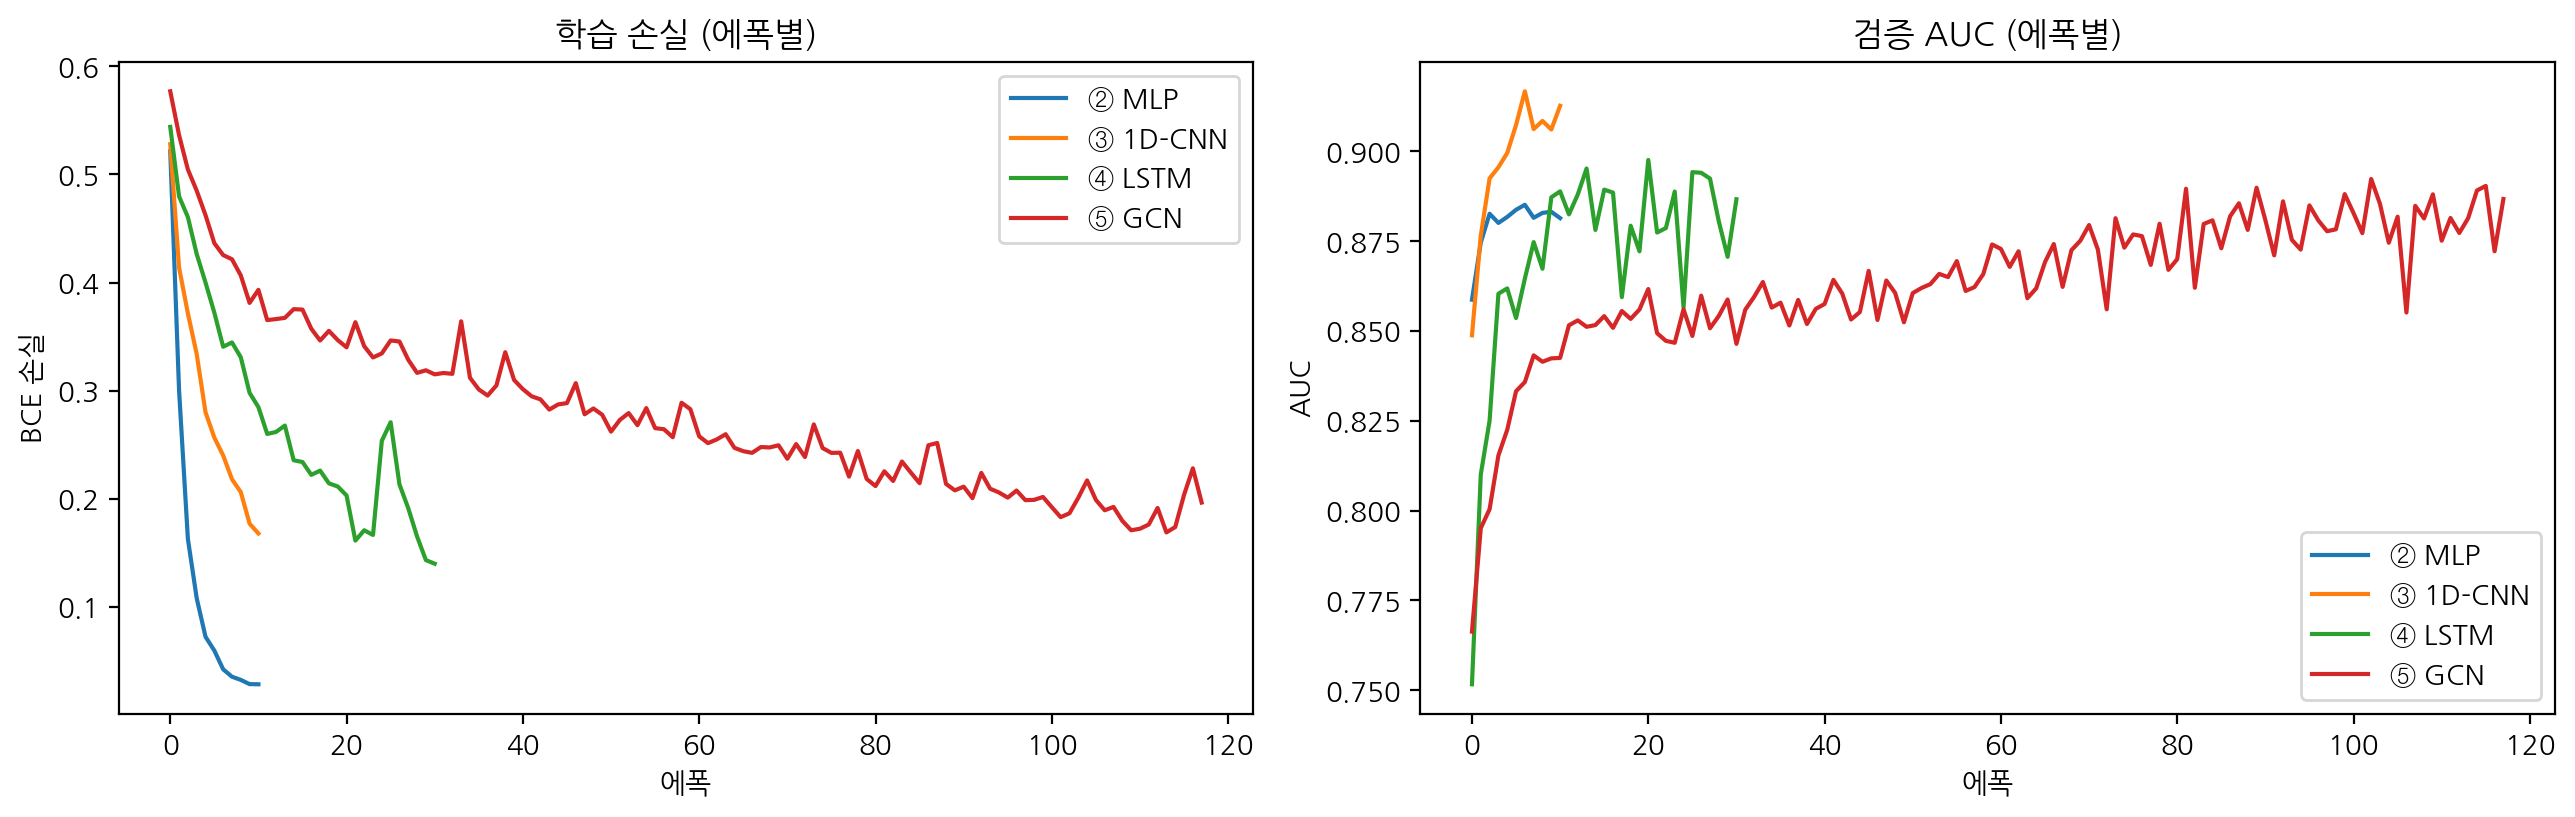

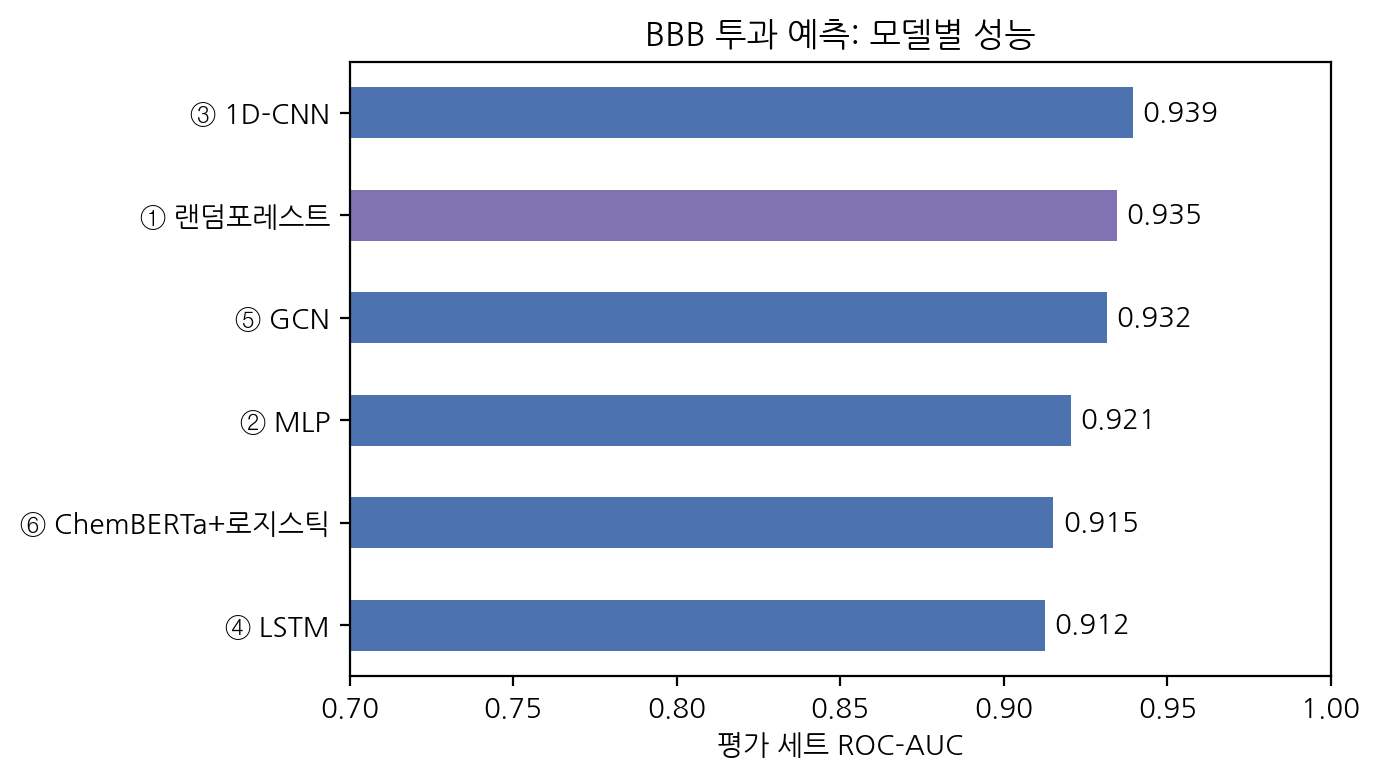

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for k, h in histories.items():
    ax[0].plot(h["train_loss"], label=k); ax[1].plot(h["val_auc"], label=k)
ax[0].set_title("학습 손실 (에폭별)"); ax[0].set_xlabel("에폭"); ax[0].set_ylabel("BCE 손실"); ax[0].legend()
ax[1].set_title("검증 AUC (에폭별)"); ax[1].set_xlabel("에폭"); ax[1].set_ylabel("AUC"); ax[1].legend()
plt.tight_layout(); plt.show()

res = pd.Series(results).sort_values()
res.plot.barh(figsize=(7, 4), color=["#8172B3" if "랜덤" in k else "#4C72B0" for k in res.index])
plt.xlim(0.7, 1.0); plt.xlabel("평가 세트 ROC-AUC"); plt.title("BBB 투과 예측: 모델별 성능")
for i, v in enumerate(res.values): plt.text(v + 0.003, i, f"{v:.3f}", va="center")
plt.tight_layout(); plt.show()

> **해석 포인트**
> - 2천 개 수준의 작은 데이터에서는 **랜덤포레스트 같은 전통 ML 이 딥러닝과 비슷하거나 더 좋은 경우가 흔합니다.**
> - 딥러닝의 장점은 **표현을 스스로 학습**한다는 것 — 데이터가 커질수록, 또는 **사전학습 모델(전이학습)** 을 쓸 때 빛납니다.
> - 같은 데이터라도 **표현형(지문·문자열·그래프·임베딩)** 이 모델 선택을 결정합니다.
> - 실행할 때마다 결과가 조금씩 다릅니다(무작위 초기화) → 실무에서는 여러 시드의 평균과 **교차검증**으로 비교 (예제 06).

| 모델 | 언제 쓰나 |
|---|---|
| RF / XGBoost + 지문 | 데이터 수천 개 이하, 빠른 기준선 |
| MLP | 지문·기술자 입력, 멀티태스크 학습 |
| CNN / RNN | 서열·시계열(SMILES, 단백질 서열, 공정 센서) |
| GNN | 분자 구조를 직접 학습, 3D 정보 확장(등변 GNN) |
| Transformer / 파운데이션 모델 | 대규모 사전학습 + 소량 데이터 미세조정, 생성 모델 |

## 🧪 LLM 코딩 과제
```
위 노트북의 GCN 클래스를 수정해서 층 수(L)를 1, 2, 3, 4 로 바꿔가며 평가 AUC 를 비교하는 코드를 써줘.
train_model(GCN(d_in, L=L), graph_batches, ...) 함수를 그대로 사용하고 결과를 막대그래프로 그려줘.
```

In [ ]:
# ✏️ LLM 코드 붙여넣기

## ✅ 정리
- 딥러닝 학습 = **미니배치 → 손실 → 역전파 → 옵티마이저**, 조기 종료로 과대적합 방지
- 분자 표현형별 모델: 지문→MLP, SMILES→CNN/RNN, 그래프→GNN, 토큰→Transformer
- **사전학습 파운데이션 모델**(ChemBERTa, MolFormer 등)의 임베딩은 소량 데이터에서 강력한 출발점
- 성능 비교는 **같은 데이터 분할**에서, 가능하면 **여러 번 반복**하여

➡️ **다음 예제 06**: 특성공학·교차검증·**하이퍼파라미터 튜닝**으로 모델을 체계적으로 최적화합니다.